In [3]:
!pip install -q torch-scatter torch-sparse torch-geometric -f https://data.pyg.org/whl/torch-2.0.0+cu118.html

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 48.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 51.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 17.8 MB/s eta 0:00:00


In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data, DataLoader
from torch_geometric.nn import GCNConv
import pandas as pd
from transformers import AutoTokenizer, AutoModel, AutoModelForTokenClassification, pipeline
from sklearn.model_selection import train_test_split

/usr/local/lib/python3.11/dist-packages/torch_geometric/typing.py:86: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: /usr/local/lib/python3.11/dist-packages/torch_scatter/_version_cuda.so: undefined symbol: _ZN3c1017RegisterOperatorsD1Ev
  warnings.warn(f"An issue occurred while importing 'torch-scatter'. "
/usr/local/lib/python3.11/dist-packages/torch_geometric/typing.py:124: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: /usr/local/lib/python3.11/dist-packages/torch_sparse/_version_cuda.so: undefined symbol: _ZN3c1017RegisterOperatorsD1Ev
  warnings.warn(f"An issue occurred while importing 'torch-sparse'. "


In [5]:
data_path = "/content/drive/MyDrive/Nam3/DLL/NCKH_DLL/fnd_dataset.csv"
df = pd.read_csv(data_path)
df = df.dropna(subset=["text"])
df = df[df["text"].str.strip() != ""]
df = df[df["label"].isin([0, 1])]
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
print(f"Train: {len(train_df)}, Test: {len(test_df)}")

Train: 188, Test: 48


In [21]:
ner_model_id = "NlpHUST/ner-vietnamese-electra-base"
ner_tokenizer = AutoTokenizer.from_pretrained(ner_model_id)
ner_model = AutoModelForTokenClassification.from_pretrained(ner_model_id)
ner_pipeline = pipeline("ner", model=ner_model, tokenizer=ner_tokenizer, aggregation_strategy="simple")

sentence_tokenizer = AutoTokenizer.from_pretrained("vinai/phobert-base")
sentence_encoder = AutoModel.from_pretrained("vinai/phobert-base")

def extract_entities(text):
    inputs = ner_tokenizer(text, truncation=True, max_length=512, return_tensors="pt")
    truncated_text = ner_tokenizer.decode(inputs["input_ids"][0], skip_special_tokens=True)
    results = ner_pipeline(truncated_text)
    return [(r['word'], r['entity_group']) for r in results]

def build_graph(post_text, label, tokenizer, encoder):
    # Dummy entity extraction (có thể thay bằng kết quả NER thực)
    entities = [(ent, 'ENTITY') for ent in post_text.split()[:5]]  # lấy 5 từ đầu làm entities mẫu

    text_node = [post_text]
    entity_nodes = [ent[0] for ent in entities]
    all_nodes = text_node + entity_nodes

    inputs = tokenizer(all_nodes, return_tensors="pt", padding=True, truncation=True, max_length=50)
    with torch.no_grad():
        outputs = encoder(**inputs)
    embeddings = outputs.last_hidden_state[:, 0, :]  # [CLS] token

    edges = [(0, i) for i in range(1, len(all_nodes))]
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()

    data = Data(x=embeddings, edge_index=edge_index)
    data.y = torch.tensor([label], dtype=torch.long)
    data.text = post_text  # ✅ để model đọc được .text
    return data

Device set to use cpu


In [25]:
train_graphs = [
    build_graph(row["text"], row["label"], sentence_tokenizer, sentence_encoder)
    for _, row in train_df.iterrows()
]
train_graphs = [g for g in train_graphs if g is not None]

test_graphs = [
    build_graph(row["text"], row["label"], sentence_tokenizer, sentence_encoder)
    for _, row in test_df.iterrows()
]
test_graphs = [g for g in test_graphs if g is not None]

print(f"Graphs built: train={len(train_graphs)}, test={len(test_graphs)}")

Graphs built: train=188, test=48


In [26]:
class KAGN(nn.Module):
    def __init__(self, num_classes=2):
        super(KAGN, self).__init__()
        self.text_encoder = AutoModel.from_pretrained("vinai/phobert-base")
        self.tokenizer = AutoTokenizer.from_pretrained("vinai/phobert-base")
        self.attention = nn.MultiheadAttention(embed_dim=768, num_heads=8, batch_first=True)
        self.gcn1 = GCNConv(768, 256)
        self.gcn2 = GCNConv(256, 128)
        self.classifier = nn.Linear(128 + 768, num_classes)

    def forward(self, batch):
        texts = [g.text for g in batch]
        device = next(self.parameters()).device

        # Encode texts
        inputs = self.tokenizer(texts, return_tensors="pt", padding=True, truncation=True, max_length=50).to(device)
        text_outputs = self.text_encoder(**inputs)
        text_cls = text_outputs.last_hidden_state[:, 0, :]

        # GCN
        x = torch.cat([g.x for g in batch], dim=0).to(device)
        edge_index = torch.cat([g.edge_index for g in batch], dim=1).to(device)
        x = F.relu(self.gcn1(x, edge_index))
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.gcn2(x, edge_index)

        # Assume each graph starts with 1 root node (text node)
        start_indices = torch.cumsum(torch.tensor([0] + [g.x.size(0) for g in batch[:-1]]), dim=0)
        root_nodes = x[start_indices]

        combined = torch.cat([text_cls, root_nodes], dim=-1)
        return self.classifier(combined)

In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_model(model, graphs):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for g in graphs:
            try:
                output = model([g])  # giữ input là list để forward() đúng
                pred = torch.argmax(output, dim=1).cpu().item()
                label = g.y.cpu().item()
                all_preds.append(pred)
                all_labels.append(label)
            except Exception as e:
                print(f"Error in batch: {e}")

    acc = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)

    print("Evaluation Results:")
    print(f"Accuracy:  {acc:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")

    return acc, precision, recall, f1

In [28]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [29]:
model = KAGN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)
loss_fn = nn.CrossEntropyLoss()

In [35]:
def plot_training_history(history):
    epochs = range(1, len(history["loss"]) + 1)
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["loss"], marker='o', label='Loss')
    plt.title("Training Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["accuracy"], marker='o', label='Accuracy')
    plt.plot(epochs, history["f1"], marker='o', label='F1-score')
    plt.plot(epochs, history["precision"], marker='o', label='Precision')
    plt.plot(epochs, history["recall"], marker='o', label='Recall')
    plt.title("Evaluation Metrics")
    plt.xlabel("Epoch")
    plt.ylabel("Score")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

In [38]:
import matplotlib.pyplot as plt

def train_model(model, train_graphs, test_graphs, epochs=10, batch_size=4):
    history = {"loss": [], "accuracy": [], "precision": [], "recall": [], "f1": []}

    for epoch in range(epochs):
        model.train()
        total_loss, count = 0, 0

        for i in range(0, len(train_graphs), batch_size):
            batch_list = train_graphs[i:i+batch_size]
            try:
                output = model(batch_list)
                labels = torch.cat([g.y for g in batch_list], dim=0).to(device)
                loss = loss_fn(output, labels)
                loss.backward()
                optimizer.step()
                optimizer.zero_grad()
                total_loss += loss.item()
                count += 1
            except Exception as e:
                print(f"Error in batch: {e}")

        avg_loss = total_loss / max(count, 1)
        print(f"\nEpoch {epoch+1}: Avg loss = {avg_loss:.4f}")
        acc, precision, recall, f1 = evaluate_model(model, test_graphs)

        # Save metrics
        history["loss"].append(avg_loss)
        history["accuracy"].append(acc)
        history["precision"].append(precision)
        history["recall"].append(recall)
        history["f1"].append(f1)

    # Plot after training
    plot_training_history(history)

    return history


Epoch 1: Avg loss = 0.2396
Evaluation Results:
Accuracy:  0.9167
F1-Score:  0.9161
Precision: 0.9161
Recall:    0.9161

Epoch 2: Avg loss = 0.0652
Evaluation Results:
Accuracy:  0.9167
F1-Score:  0.9165
Precision: 0.9167
Recall:    0.9196

Epoch 3: Avg loss = 0.0173
Evaluation Results:
Accuracy:  0.9375
F1-Score:  0.9373
Precision: 0.9365
Recall:    0.9388

Epoch 4: Avg loss = 0.0095
Evaluation Results:
Accuracy:  0.9375
F1-Score:  0.9373
Precision: 0.9365
Recall:    0.9388

Epoch 5: Avg loss = 0.0061
Evaluation Results:
Accuracy:  0.9375
F1-Score:  0.9373
Precision: 0.9365
Recall:    0.9388

Epoch 6: Avg loss = 0.0048
Evaluation Results:
Accuracy:  0.9375
F1-Score:  0.9373
Precision: 0.9365
Recall:    0.9388

Epoch 7: Avg loss = 0.0039
Evaluation Results:
Accuracy:  0.9375
F1-Score:  0.9373
Precision: 0.9365
Recall:    0.9388

Epoch 8: Avg loss = 0.0031
Evaluation Results:
Accuracy:  0.9375
F1-Score:  0.9373
Precision: 0.9365
Recall:    0.9388

Epoch 9: Avg loss = 0.0027
Evaluation R

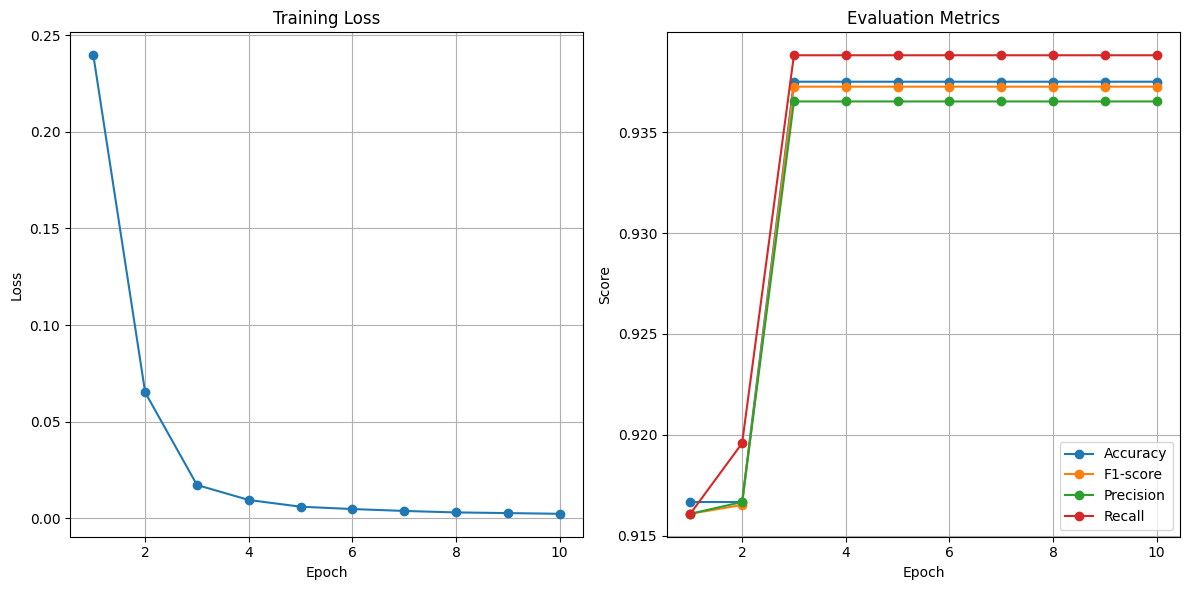

{'loss': [0.23958303725862123,
  0.06517066208130502,
  0.017291130656574633,
  0.009516947446985448,
  0.0060501098236505025,
  0.004837225250741269,
  0.003860278431563935,
  0.0030848613613225677,
  0.0027462752174308644,
  0.0023800097975602494],
 'accuracy': [0.9166666666666666,
  0.9166666666666666,
  0.9375,
  0.9375,
  0.9375,
  0.9375,
  0.9375,
  0.9375,
  0.9375,
  0.9375],
 'precision': [0.916083916083916,
  0.9166666666666667,
  0.9365217391304348,
  0.9365217391304348,
  0.9365217391304348,
  0.9365217391304348,
  0.9365217391304348,
  0.9365217391304348,
  0.9365217391304348,
  0.9365217391304348],
 'recall': [0.916083916083916,
  0.9195804195804196,
  0.9388111888111889,
  0.9388111888111889,
  0.9388111888111889,
  0.9388111888111889,
  0.9388111888111889,
  0.9388111888111889,
  0.9388111888111889,
  0.9388111888111889],
 'f1': [0.916083916083916,
  0.9165217391304348,
  0.9372549019607843,
  0.9372549019607843,
  0.9372549019607843,
  0.9372549019607843,
  0.93725490

In [39]:
train_model(model, train_graphs, test_graphs)

In [41]:
!jupyter nbconvert --to html /content/drive/MyDrive/"Colab Notebooks"/KAGN_FakeNewsDetection_REBUILT.ipynb

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/KAGN_FakeNewsDetection_REBUILT.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 399468 bytes to /content/drive/MyDrive/Colab Notebooks/KAGN_FakeNewsDetection_REBUILT.html
